Ata Bakhadirov

In [3]:
!pip install empiricaldist

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm, pearsonr, spearmanr
from empiricaldist import Cdf, Pmf

plt.rcParams['figure.figsize'] = (6.5, 4.2)

df = pd.read_csv('energy_health_2019.csv')
src = pd.read_csv('death_rates_by_source.csv')
df.shape

(183, 19)

1. DATAFRAME Inspection

In [4]:
df.head()

,country,iso_code,death_rate_ambient_per100k,population,gdp,electricity_generation,fossil_share_elec,coal_share_elec,gas_share_elec,oil_share_elec,biofuel_share_elec,nuclear_share_elec,hydro_share_elec,wind_share_elec,solar_share_elec,renewables_share_elec,low_carbon_share_elec,coal_electricity,gdp_per_capita
0,Afghanistan,AFG,143,37856125.0,7.308570e+10,1.46,12.329,5.479,0.000,6.849,0.000,0.0,83.562,0.000,4.110,87.671,87.671,0.08,1931.0
1,Albania,ALB,59,2885011.0,3.328975e+10,5.20,0.000,0.000,0.000,0.000,0.000,0.0,99.615,0.000,0.385,100.000,100.000,0.00,11539.0
2,Algeria,DZA,48,43294551.0,5.899051e+11,81.61,98.934,0.000,98.468,0.466,0.000,0.0,0.184,0.012,0.870,1.066,1.066,0.00,13625.0
3,Angola,AGO,60,32375633.0,1.614089e+11,15.82,26.802,0.000,10.367,16.435,0.316,0.0,72.756,0.000,0.126,73.198,73.198,0.00,4986.0
4,Antigua and Barbuda,ATG,19,91377.0,NaN,0.36,97.222,0.000,0.000,97.222,0.000,0.0,0.000,0.000,2.778,2.778,2.778,0.00,NaN


In [5]:
# Which countries are missing the electricity mix? Drop them.
print('Missing fossil share:', df.loc[df['fossil_share_elec'].isna(), 'country'].tolist())
df = df.dropna(subset=['fossil_share_elec']).copy()
print('Countries analysed:', len(df))
print('Missing GDP per capita:', df['gdp_per_capita'].isna().sum(), '(excluded only from GDP-based steps)')

Missing fossil share: ['Micronesia (country)']
Countries analysed: 182
Missing GDP per capita: 22 (excluded only from GDP-based steps)


In [8]:
# Most and least affected countries
cols = ['country','fossil_share_elec','death_rate_ambient_per100k','gdp_per_capita']
display(df.nlargest(8, 'death_rate_ambient_per100k')[cols].round(1))
display(df.nsmallest(8, 'death_rate_ambient_per100k')[cols].round(1))

,country,fossil_share_elec,death_rate_ambient_per100k,gdp_per_capita
161,Tajikistan,8.5,159,4300.0
0,Afghanistan,12.3,143,1931.0
109,Mongolia,90.1,120,13607.0
176,Uzbekistan,89.8,117,10314.0
9,Azerbaijan,93.1,114,16384.0
180,Yemen,85.4,109,1885.0
50,Egypt,90.2,105,11987.0
125,Pakistan,63.1,105,5079.0


,country,fossil_share_elec,death_rate_ambient_per100k,gdp_per_capita
58,Finland,18.7,7,39874.0
29,Canada,19.3,8,45228.0
74,Iceland,0.0,8,43112.0
123,Norway,2.1,8,85140.0
158,Sweden,2.0,8,45434.0
7,Australia,79.2,10,49269.0
10,Bahamas,100.0,10,NaN
59,France,9.5,10,40232.0


Notice Tajikistan (8.5% fossil, rate 159) and Afghanistan (12.3% fossil, rate 143) — near the top of the death-rate ranking with very low fossil electricity. Their outdoor pollution comes from other sources (household fuel burning, dust, vehicles), not their grids. Cases like these are why this relationship is weak.

2. Distribution

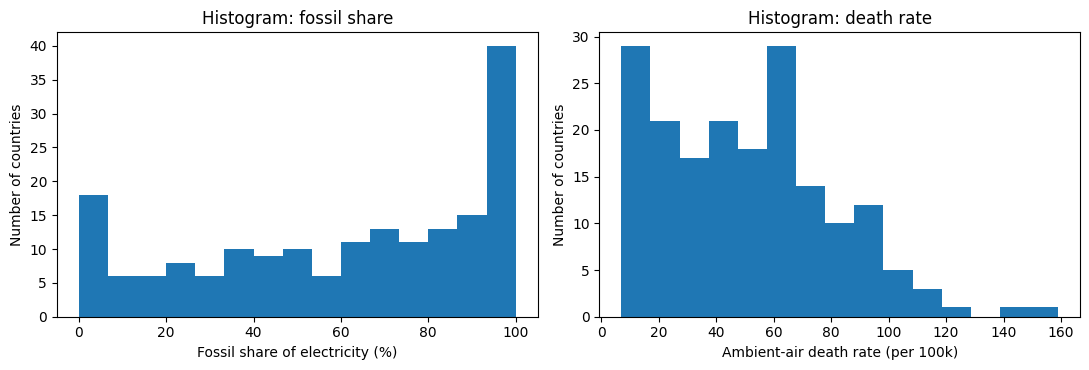

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
x.hist(ax=axes[0], bins=15, grid=False); axes[0].set(xlabel='Fossil share of electricity (%)', ylabel='Number of countries', title='Histogram: fossil share')
y.hist(ax=axes[1], bins=15, grid=False); axes[1].set(xlabel='Ambient-air death rate (per 100k)', ylabel='Number of countries', title='Histogram: death rate')
plt.tight_layout();

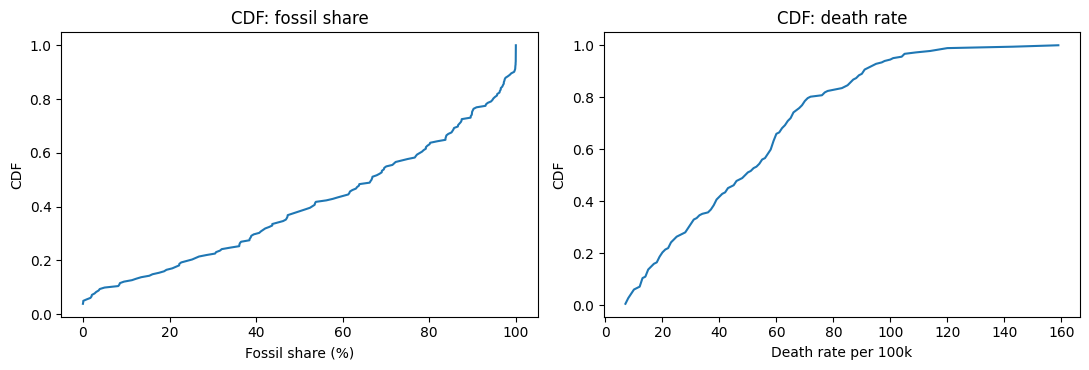

In [12]:
cdf_x = Cdf.from_seq(x); cdf_y = Cdf.from_seq(y)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
cdf_x.plot(ax=axes[0]); axes[0].set(xlabel='Fossil share (%)', ylabel='CDF', title='CDF: fossil share')
cdf_y.plot(ax=axes[1]); axes[1].set(xlabel='Death rate per 100k', ylabel='CDF', title='CDF: death rate')
plt.tight_layout()

About 25% of countries run on ≥90% fossil electricity (the CDF of fossil share rises slowly then jumps at the right edge), and about 20% have death rates ≤ 20 per 100k. The middle half of countries sits between 24 and 68 deaths per 100k.

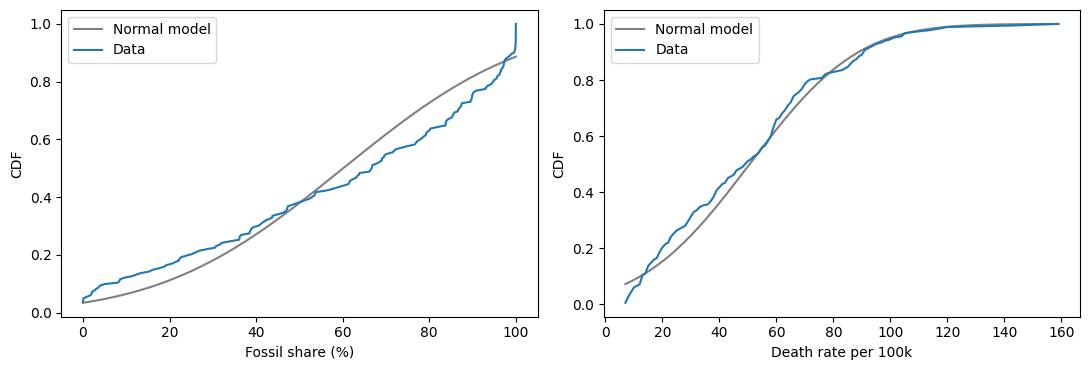

In [11]:
# Is a normal distribution a good model?
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, s, label in [(axes[0], x, 'Fossil share (%)'), (axes[1], y, 'Death rate per 100k')]:
    qs = np.linspace(s.min(), s.max(), 200)
    ax.plot(qs, norm(s.mean(), s.std()).cdf(qs), color='gray', label='Normal model')
    Cdf.from_seq(s).plot(ax=ax, label='Data')
    ax.set(xlabel=label, ylabel='CDF'); ax.legend()
plt.tight_layout();

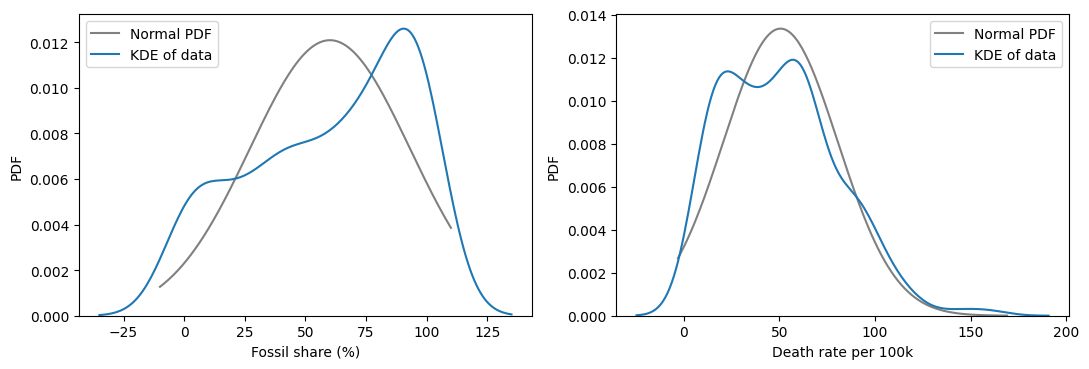

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, s, label in [(axes[0], x, 'Fossil share (%)'), (axes[1], y, 'Death rate per 100k')]:
    xs = np.linspace(s.min()-10, s.max()+10, 200)
    ax.plot(xs, norm(s.mean(), s.std()).pdf(xs), color='gray', label='Normal PDF')
    sns.kdeplot(s, ax=ax, label='KDE of data')
    ax.set(xlabel=label, ylabel='PDF'); ax.legend()
plt.tight_layout();

Neither variable is well modelled by a normal distribution. Fossil share piles up at both ends (many ~0–10% and many ~90–100% grids), a bimodal / U-shaped pattern; the death rate is right-skewed. (the CDF/KDE comparison is the more informative evidence.) Practically: prefer medians, IQR and rank-based (Spearman) correlation over means/SDs and Pearson alone.

3. Relationship: fossil share vs death rate.

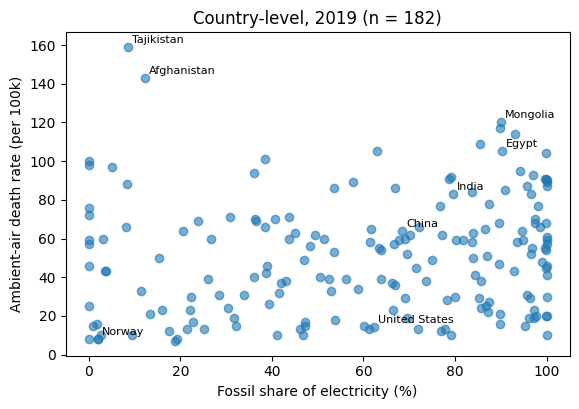

Pearson r = 0.14 (p = 0.055),  R² = 0.020
Spearman rho = 0.18 (p = 0.014)


In [14]:
plt.scatter(x, y, alpha=0.6)
plt.xlabel('Fossil share of electricity (%)'); plt.ylabel('Ambient-air death rate (per 100k)')
plt.title('Country-level, 2019 (n = 182)')
for c in ['Tajikistan','Afghanistan','Mongolia','Egypt','India','China','United States','Norway']:
    r = df[df['country']==c].iloc[0]
    plt.annotate(c, (r['fossil_share_elec'], r['death_rate_ambient_per100k']), fontsize=8, xytext=(3,3), textcoords='offset points')
plt.show()

r_p, p_p = pearsonr(x, y); r_s, p_s = spearmanr(x, y)
print(f'Pearson r = {r_p:.2f} (p = {p_p:.3f}),  R² = {r_p**2:.3f}')
print(f'Spearman rho = {r_s:.2f} (p = {p_s:.3f})')

In [15]:
df['fossil_bin'] = pd.cut(df['fossil_share_elec'], [-1, 25, 50, 75, 100.1], labels=['0–25%','25–50%','50–75%','75–100%'])
df.groupby('fossil_bin', observed=True)['death_rate_ambient_per100k'].agg(['count','mean','median','std']).round(1)

,count,mean,median,std
fossil_bin,,,,
0–25%,36,46.6,38.0,38.9
25–50%,33,44.2,40.0,24.8
50–75%,36,47.3,47.0,22.7
75–100%,77,56.7,58.0,29.5


The relationship is positive but weak. r = 0.14, ρ = 0.18. Countries with ≥75% fossil electricity have a median death rate of 58 vs 38–47 for lower-fossil groups, but the spread inside every group is enormous (SD 23–39). On this data, fossil share explains almost none of the variation in death rates.

In [17]:
# The variable that does have an effect: national income


d2['income_group'] = pd.qcut(d2['gdp_per_capita'], 3, labels=['Low income','Middle income','High income'])
rows = []
for g, sub in d2.groupby('income_group', observed=True):
    r, p = pearsonr(sub['fossil_share_elec'], sub['death_rate_ambient_per100k'])
    rows.append({'group': g, 'n': len(sub), 'median GDP/cap': sub['gdp_per_capita'].median(), 'median death rate': sub['death_rate_ambient_per100k'].median(), 'r (fossil vs death)': round(r,2), 'p': round(p,3)})
pd.DataFrame(rows)

,group,n,median GDP/cap,median death rate,r (fossil vs death),p
0,Low income,53,2261.0,71.0,-0.04,0.781
1,Middle income,53,12379.0,54.0,0.34,0.012
2,High income,54,36182.0,18.5,0.54,0.000


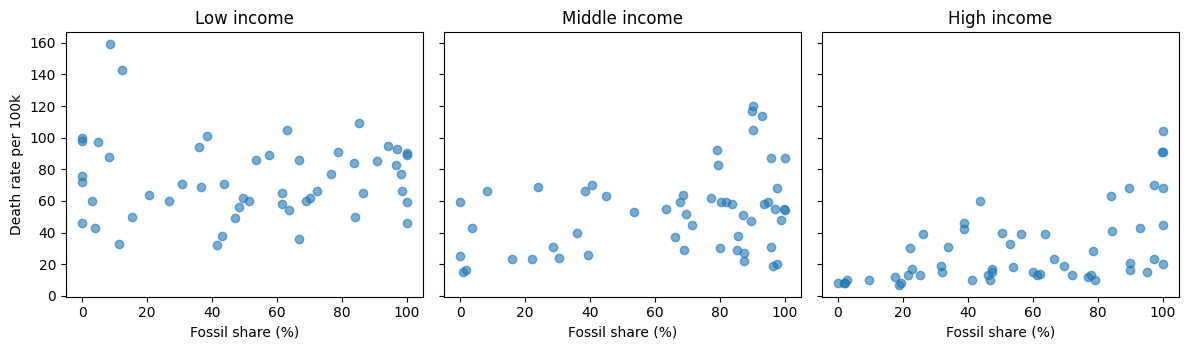

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
for ax, (g, sub) in zip(axes, d2.groupby('income_group', observed=True)):
    ax.scatter(sub['fossil_share_elec'], sub['death_rate_ambient_per100k'], alpha=0.6)
    ax.set(title=g, xlabel='Fossil share (%)')
axes[0].set_ylabel('Death rate per 100k')
plt.tight_layout();

Income dominates. Death rate is strongly tied to GDP per capita (r ≈ −0.56) while fossil share is essentially unrelated to it (r ≈ 0.07). Splitting countries into income thirds shows the fossil–death link is ~0 in low-income countries, moderate in middle-income (r ≈ 0.33) and clearest in high-income (r ≈ 0.56).

4. Comparing groups: Nuclear vs Coal.

nuclear >= 10% of electricity: 20 countries | median death rate 17.0 | median GDP/cap 36828
coal    >= 40% of electricity: 22 countries | median death rate 58.5 | median GDP/cap 14295


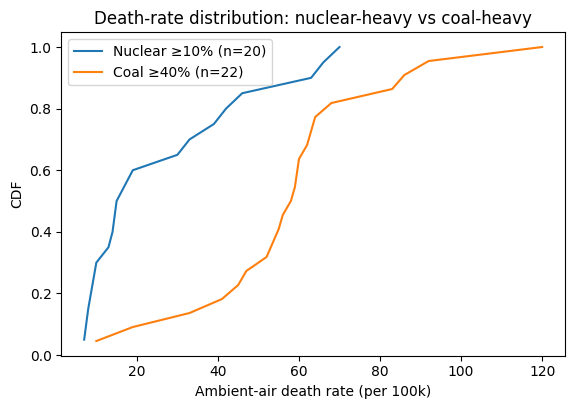

In [19]:
nuclear_heavy = df[df['nuclear_share_elec'] >= 10]
coal_heavy    = df[df['coal_share_elec'] >= 40]
print('nuclear >= 10% of electricity:', len(nuclear_heavy), 'countries | median death rate', nuclear_heavy['death_rate_ambient_per100k'].median(), '| median GDP/cap', round(nuclear_heavy['gdp_per_capita'].median()))
print('coal    >= 40% of electricity:', len(coal_heavy),    'countries | median death rate', coal_heavy['death_rate_ambient_per100k'].median(),    '| median GDP/cap', round(coal_heavy['gdp_per_capita'].median()))

Cdf.from_seq(nuclear_heavy['death_rate_ambient_per100k']).plot(label=f'Nuclear ≥10% (n={len(nuclear_heavy)})')
Cdf.from_seq(coal_heavy['death_rate_ambient_per100k']).plot(label=f'Coal ≥40% (n={len(coal_heavy)})')
plt.xlabel('Ambient-air death rate (per 100k)'); plt.ylabel('CDF'); plt.title('Death-rate distribution: nuclear-heavy vs coal-heavy'); plt.legend();

The nuclear-heavy CDF sits clearly left of the coal-heavy one (median 17 vs 58.5). But the groups are not comparable: nuclear-heavy countries are rich (median GDP/capita ≈  36.8k) and mostly in Europe/North America while coal heavy ones are poorer(≈ 14.3k), this comparison mixes the fuel effect with the wealth effect — they cannot be separated.

6. Does diversification matter?

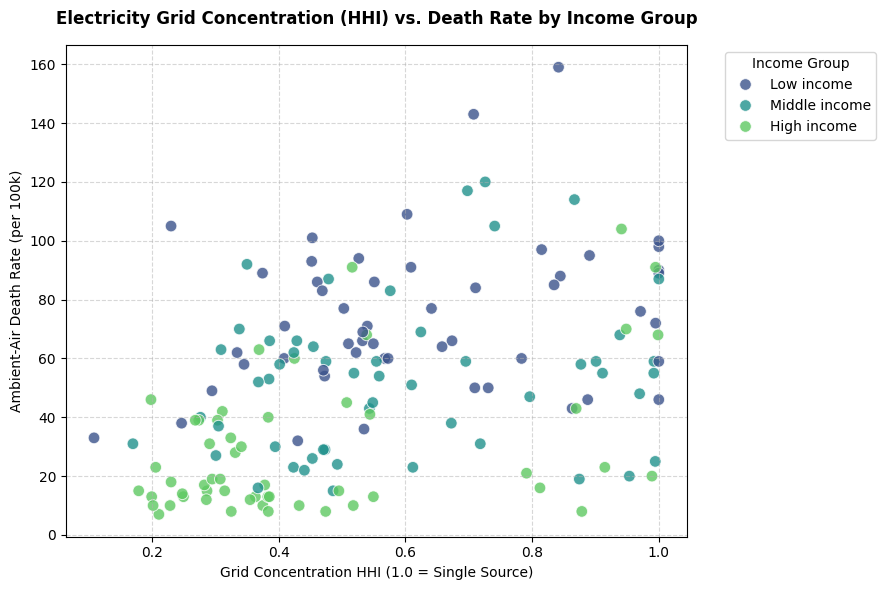

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

# Recreate d2 inline to avoid runtime NameErrors
d2 = df.dropna(subset=['gdp_per_capita']).copy()
d2['log_gdp'] = np.log10(d2['gdp_per_capita'])
d2['income_group'] = pd.qcut(d2['gdp_per_capita'], 3, labels=['Low income','Middle income','High income'])

# Create a visualization to make the HHI vs Death Rate relationship clear and readable
plt.figure(figsize=(9, 6))

# Calculate HHI
mix = ['coal_share_elec','gas_share_elec','oil_share_elec','biofuel_share_elec','nuclear_share_elec','hydro_share_elec','wind_share_elec','solar_share_elec']
d2['hhi'] = ((d2[mix].fillna(0) / 100) ** 2).sum(axis=1)

# Scatter plot colored by income group
sns.scatterplot(
    data=d2,
    x='hhi',
    y='death_rate_ambient_per100k',
    hue='income_group',
    palette='viridis',
    alpha=0.8,
    s=70
)

plt.title('Electricity Grid Concentration (HHI) vs. Death Rate by Income Group', fontsize=12, fontweight='bold', pad=15)
plt.xlabel('Grid Concentration HHI (1.0 = Single Source)', fontsize=10)
plt.ylabel('Ambient-Air Death Rate (per 100k)', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Income Group', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

Countries with more concentrated power grids (less diversified energy sources) tend to have higher death rates from air pollution. A concentrated grid is not always a bad grid. For example, a country that runs on 100% clean hydro power has the same "concentration" score as one that runs on 100% dirty coal. Therefore, grid concentration is mostly a proxy for a nation's wealth, not its environmental cleanliness.

7. SUMMARY
The headline relationship is weak. fossil share → ambient-air death rate: Pearson r = 0.14 (p = 0.055), Spearman ρ = 0.18 (p = 0.014).
Income explains far more of the variation in death rates than electricity mix does (r ≈ −0.56).